# Downstream analysis on Visium HD data of mouse small intestine

In [1]:
# Importing packages
import os
import metachat as mc
import scanpy as sc

import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.cluster import KMeans
rcParams['pdf.fonttype'] = 42
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# This notebook expects to run from the folder that contains the `datasets/`
# directory downloaded from Zenodo. If you started Jupyter somewhere else,
# point it here first, for example:
#     os.chdir("/path/to/the/folder/that/contains/datasets")


## Import MetaChat results 

In [3]:
adata = sc.read('datasets/mouse_small_intestine/metachat_result.h5ad')
adata.obs['Cluster'] = adata.obs['Cluster'].astype(str).astype('category')

In [4]:
adata

AnnData object with n_obs × n_vars = 3264 × 20143
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'Cluster', 'barrier_shapes', 'barrier', 'LRC_Blood_marker_Myh11', 'LRC_Blood_marker_Mgp', 'LRC_Blood_marker_Cldn5', 'LRC_Blood_avg_markers', 'LRC_Blood_marker_unfiltered', 'LRC_Blood_marker_filtered', 'visualize_LRC_marker', 'LRC_Blood_closepoint_cluster1'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Cluster_colors', 'LRC_Blood_marker_filtered_colors', 'LRC_Blood_marker_unfiltered_colors', 'MetaChat-MetaChatDB-info', 'barrier_shapes', 'df_metasen_filtered', 'log1p', 'non_visible_pair', 'spatial', 'spatialdata_attrs', 'visualize_LRC_marker_colors'
    obsm: 'MetaChat-MetaChatDB-sum-receiver', 'MetaChat-MetaChatDB-sum-sender', 'spatial'
    obsp: 'LRC_shortest_Blood_dist80_cluster1', 'MetaChat-MetaChatDB-receiver-HMDB0000011-Hcar2', 'MetaChat-MetaChatDB-receiver-HMDB0000011-Slc16a7', 'MetaChat-MetaChatDB-receiver-HMDB0000011-Slc5a8', 'MetaChat-MetaChatDB-

## Compute group-level MCC of all pairs

To cluster MCC flow among all pairs, we need to compute group-level MCCs across all metabolite–sensor pairs.

In [5]:
# extract all_ms_pairs
df_metasen_filtered = adata.uns['df_metasen_filtered']
all_ms_pairs = (df_metasen_filtered['HMDB.ID'] + '-' + df_metasen_filtered['Sensor.Gene']).tolist()

In [6]:
mc.tl.communication_flow(adata = adata,
                         database_name = 'MetaChatDB',
                         sum_ms_pairs = all_ms_pairs,
                         k = 10)

Similarly, since the small intestine tissue is rolled, we used Napari to manually select a representative subregion for MCC flow clustering.
Here, we directly import the preprocessed results of this selected subregion for further analysis.

In [7]:
adata = sc.read_h5ad('datasets/mouse_small_intestine/metachat_result_flow_subset.h5ad')
adata_sub = adata[adata.obs['subset_direction_shapes'] == True]

In [8]:
adata

AnnData object with n_obs × n_vars = 3264 × 20143
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'Cluster', 'barrier_shapes', 'barrier', 'LRC_Blood_marker_Myh11', 'LRC_Blood_marker_Mgp', 'LRC_Blood_marker_Cldn5', 'LRC_Blood_avg_markers', 'LRC_Blood_marker_unfiltered', 'LRC_Blood_marker_filtered', 'visualize_LRC_marker', 'LRC_Blood_closepoint_cluster1', 'subset_direction_shapes'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Cluster_colors', 'LRC_Blood_marker_filtered_colors', 'LRC_Blood_marker_unfiltered_colors', 'MetaChat-MetaChatDB-info', 'barrier_shapes', 'df_metasen_filtered', 'log1p', 'non_visible_pair', 'spatial', 'spatialdata_attrs', 'visualize_LRC_marker_colors'
    obsm: 'MetaChat-MetaChatDB-sum-receiver', 'MetaChat-MetaChatDB-sum-sender', 'MetaChat-vf-MetaChatDB-receiver-HMDB0000011-Hcar2', 'MetaChat-vf-MetaChatDB-receiver-HMDB0000011-Slc16a7', 'MetaChat-vf-MetaChatDB-receiver-HMDB0000011-Slc5a8', 'MetaChat-vf-MetaChatDB-receiver-HMDB000001

As an example, we show the flow of one metabolite-sensor pair, cholic acid
sensed through the bile-acid transporter `Slc10a2`. Any pair present in
`adata.uns['df_metasen_filtered']` can be used here.


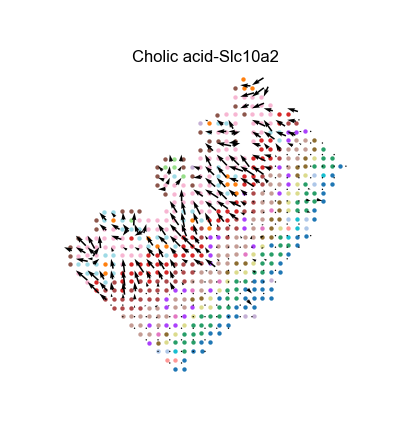

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))
pl = mc.pl.plot_communication_flow(
    adata = adata_sub, 
    database_name = 'MetaChatDB',
    ms_pair_name = 'HMDB0000619-Slc10a2',   # Cholic acid - Slc10a2
    plot_method = 'grid',
    background = 'group',
    group_name = 'Cluster',
    summary = 'receiver',
    ndsize = 10,
    largest_arrow = 0.05,
    normalize_v_quantile = 0.995,
    grid_density = 0.5,
    title = 'Cholic acid-Slc10a2',
    ax = ax)

In this step, we compute the directional histograms of MCC (metabolite–sensor) flow vectors for all selected pairs. For each pair, the communication flow field is first sampled on a regular spatial grid (controlled by grid_density), and grid points with zero vectors across all pairs are excluded.
Then, the angle of each nonzero vector is calculated using atan2(Vy, Vx) and binned into 18 angular intervals, while an additional bin records the fraction of zero vectors.
The resulting 19-dimensional histogram represents the directional pattern of each M–S pair, which can be used for downstream analyses such as flow clustering or pathway-level comparison.

In [10]:
df_hist, coords_ref = mc.tl.compute_direction_histogram_per_pair(
    adata = adata_sub,
    database_name = "MetaChatDB",
    all_ms_pairs = all_ms_pairs,
    summary = "receiver",
    grid_density = 0.5,
    n_bins = 18,
    eps = 1e-4
)

Filtered out 373 all-zero grids, kept 302.


Computed 1065 flows × 19 bins (after filtering).


In [11]:
df_filt = df_hist[df_hist["dir_bin_zero"] <= 0.9].copy()
print(f"Kept {len(df_filt)} / {len(df_hist)} pairs (zero ≤ 0.9).")

Kept 295 / 1065 pairs (zero ≤ 0.9).


The last column represents the proportion of zero vectors. Here, we cluster the directional histograms of the first 18 bins.

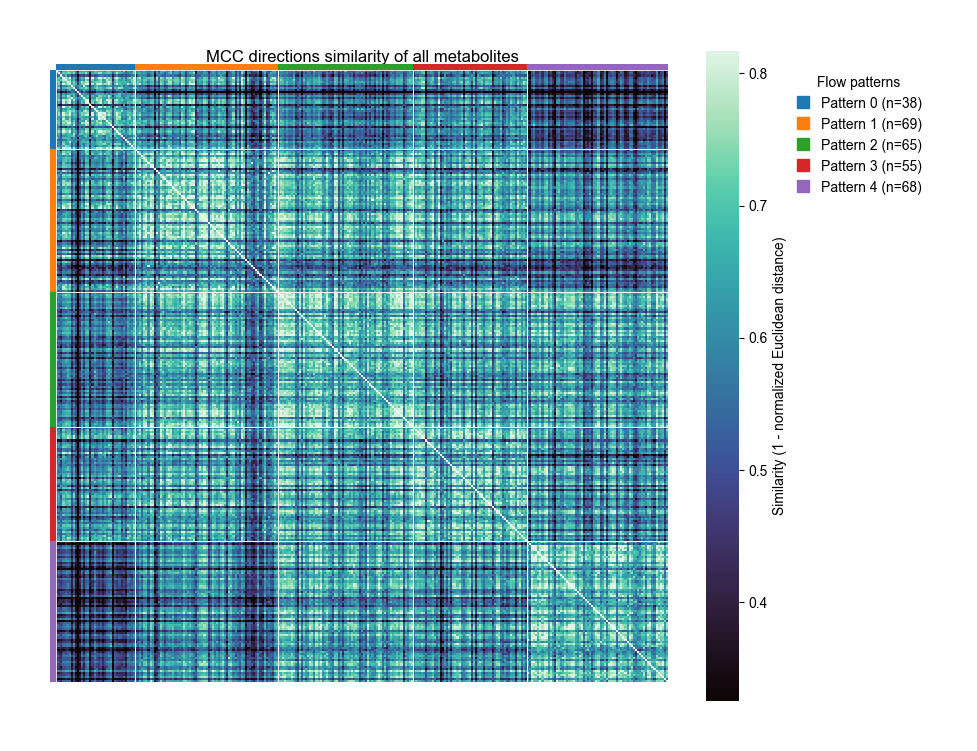

In [12]:
kmeans = KMeans(n_clusters=5, random_state=0, n_init=50)
X = df_filt[[f"dir_bin_{i}" for i in range(18)]]
labels = kmeans.fit_predict(X)

mc.pl.plot_direction_similarity(
    df_direction=df_filt[[f"dir_bin_{i}" for i in range(18)]],
    cluster_labels=labels,
    cmap="mako",
    title="MCC directions similarity of all metabolites"
)